# Lab 02 · Part A — NumPy and Homework 1
**First 60 minutes.** Then open [Part B: the perceptron](../02_Perceptron/01_Perceptron.ipynb)
or its [projector view](../90_HTML/02_Perceptron-proiector.html).

## Goal
Read array shapes, select and reduce data, distinguish elementwise from matrix multiplication,
and translate matrix operations into plain Python for Homework 1.

**Scope:** NumPy exercises and linear systems follow the official Lab02. Part B is an additional
classroom explanation of the published perceptron course, requested by your teacher.
**Homework 1 must use Python lists and standard Python, without NumPy or a linear algebra framework.**
NumPy here is a way to explore the mathematics, not an allowed homework implementation.

## Setup
CPU only; data are included. Select **RN 2026 (local)** on the classroom machine.
For a fresh environment: `python -m pip install -r requirements-lab02.txt`.
On Colab upload the notebook; it needs NumPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
plt.rcParams.update({'font.size':12,'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
BLUE, ORANGE = '#1768ac', '#c76319'
print('NumPy', np.__version__)

NumPy 2.5.3


## Steps
### 1 · Shapes, indexing and reductions (0–12 min)
A matrix has rows and columns. Before Run: what are the shapes of `A`, `A[0]`, `A[:, 0]`,
and `A.T`? What is the difference between summing over axis 0 and axis 1?

In [2]:
A = np.array([[1., 2., 3.], [4., 5., 6.]])
print('A:', A, '\nshape:', A.shape)
print('row 0:', A[0], 'column 0:', A[:, 0])
print('column sums (axis 0):', A.sum(axis=0))
print('row sums (axis 1):', A.sum(axis=1))
print('transpose:', A.T)

A: [[1. 2. 3.]
 [4. 5. 6.]] 
shape: (2, 3)
row 0: [1. 2. 3.] column 0: [1. 4.]
column sums (axis 0): [5. 7. 9.]
row sums (axis 1): [ 6. 15.]
transpose: [[1. 4.]
 [2. 5.]
 [3. 6.]]


`*` multiplies element by element; `@` takes row dot products. Broadcasting repeats the
vector along rows. Predict both outputs, then connect each row of `A @ x` to an equation.

In [3]:
A = np.array([[2., 1.], [1., 2.]])
x = np.array([2., 3.])
print('A * x (shape 2×2):\n', A * x)
print('A @ x (shape 2):', A @ x)
print('sum of each row of A * x:', (A * x).sum(axis=1))
assert np.allclose((A*x).sum(axis=1), A@x)

A * x (shape 2×2):
 [[4. 3.]
 [2. 6.]]
A @ x (shape 2): [7. 8.]
sum of each row of A * x: [7. 8.]


### 2 · Masks: select first, then count (12–22 min)
Official NumPy exercise data: **1 = spam, 0 = ordinary mail**. No classifier is trained here.
`&` combines array conditions; use parentheses. The count of `True` values is a reduction.

In [4]:
actual = np.array([1,1,1,1,0,0,1,0,0,0])
predicted = np.array([1,1,1,0,1,0,1,1,0,0])
missed_spam = (actual == 1) & (predicted == 0)
print('missed-spam mask:', missed_spam)
print('message IDs:', np.flatnonzero(missed_spam)+1)
print('missed spam count:', np.count_nonzero(missed_spam))

missed-spam mask: [False False False  True False False False False False False]
message IDs: [4]
missed spam count: 1


**A1 (5 min):** return `(TP, FP, FN, TN)` using masks, then compute accuracy.
TP = actual 1 / predicted 1; FP = actual 0 / predicted 1; FN = actual 1 / predicted 0;
TN = actual 0 / predicted 0. Inputs are nonempty, same-length 1D binary arrays.
Continue the official [NumPy exercises](02_Exercitii_NumPy.ipynb) for F1 and benchmarking;
[MetricsPractice.ipynb](../03_Optional/02_Metrici.ipynb) provides extra explanations after class.

In [5]:
def counts_numpy(gt, pred):
    # TODO: four Boolean masks and counts; return TP, FP, FN, TN.
    return None
result=counts_numpy(actual,predicted)
if result is None: print('A1: NOT ATTEMPTED')
else:
    assert tuple(result)==(4,2,1,3)
    tp,fp,fn,tn=result
    print('counts:',result,'accuracy:',(tp+tn)/len(actual))

A1: NOT ATTEMPTED


### 3 · Copies matter when replacing matrix columns (22–30 min)
The homework's Cramer matrices replace a column. A shallow copy of a nested Python list
still shares the rows. NumPy slices may also share data. Predict which originals change.

In [6]:
original = [[2,1],[1,2]]
shallow = original.copy()
shallow[0][0] = 99
print('shallow-copy mutation reaches original:', original)
original = [[2,1],[1,2]]
independent = [row.copy() for row in original]
independent[0][0] = 99
print('row copies preserve original:',original)
arr = np.array([[2,1],[1,2]])
view = arr[:,0]
copy = arr[:,0].copy()
view[0] = 99
print('NumPy original:',arr.tolist(),'independent column:',copy.tolist())

shallow-copy mutation reaches original: [[99, 1], [1, 2]]
row copies preserve original: [[2, 1], [1, 2]]
NumPy original: [[99, 1], [1, 2]] independent column: [2, 1]


### 4 · A·x = B: equations and transformations (30–42 min)
Two ticket bundles cost 7 and 8 units: `2x + y = 7`, `x + 2y = 8`.
Every equation is a line. The intersection satisfies both.
A zero determinant means no inverse: the system may have no solution or infinitely many.

solution: [2. 3.] residual: [0. 0.]


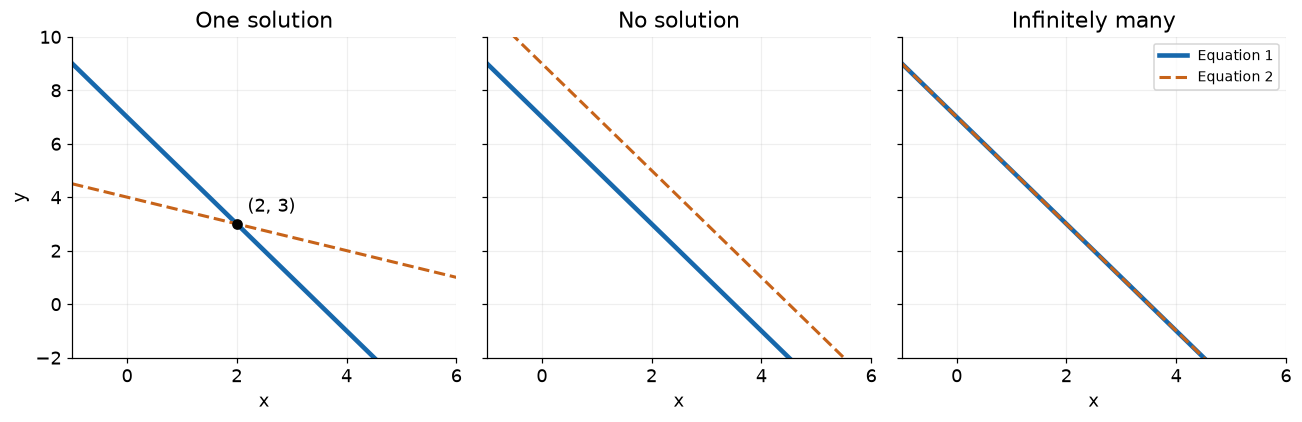

In [7]:
A=np.array([[2.,1.],[1.,2.]])
B=np.array([7.,8.])
solution=np.linalg.solve(A,B) # demonstration only: prohibited in Homework 1
print('solution:',solution,'residual:',A@solution-B)
u=np.linspace(-1,6,120)
fig,axes=plt.subplots(1,3,figsize=(12,4),sharex=True,sharey=True)
for ax,title,v1,v2 in zip(axes,['One solution','No solution','Infinitely many'],
                         [7-2*u]*3,[(8-u)/2,9-2*u,7-2*u]):
    ax.plot(u,v1,color=BLUE,label='Equation 1',lw=3)
    ax.plot(u,v2,color=ORANGE,ls='--',label='Equation 2',lw=2)
    ax.set(title=title,xlabel='x',xlim=(-1,6),ylim=(-2,10));ax.grid(alpha=.2)
axes[0].set_ylabel('y');axes[0].scatter(*solution,color='black',zorder=4)
axes[0].annotate('(2, 3)',solution,xytext=(7,8),textcoords='offset points')
axes[2].legend(fontsize=9);fig.tight_layout();plt.show()

**On paper:** determinant `ad−bc = 3`. Replace the first column with B: determinant 6 → x=2.
Replace the second column: determinant 9 → y=3. Verify both equations.

**A2 (6 min):** implement a matrix-vector product using **plain Python lists**.
For a 2×2 matrix and a length-2 vector, return the two row dot products.

In [8]:
def matvec_2x2(matrix, vector):
    # TODO: standard Python only
    return None
answer=matvec_2x2([[2,1],[1,2]],[2,3])
if answer is None: print('A2: NOT ATTEMPTED')
else:
    assert answer==[7,8]
    assert matvec_2x2([[1,0],[0,1]],[-2,5])==[-2,5]
    print('A2: checks passed')

A2: NOT ATTEMPTED


### 5 · Translate the ideas into Homework 1 (42–55 min)
Open [Assignment1.ipynb](03_Tema_1.ipynb), with [system.txt](system.txt) beside it.
The graded system is 3×3, different from our ticket example.

| Task | Implementation idea | Test it with |
|---|---|---|
| Parse equations (1 point) | split tokens; signs; implicit coefficients ±1 | `x - y + 4z = 6` |
| Determinant, trace, norm, transpose, matvec (5) | list indexing, sums, loops | identity / diagonal matrices |
| Cramer (1) | copy rows, replace one column, determinant ratio | verify original A is unchanged |
| Inverse / adjugate (3) | minors → signed cofactors → transpose → divide by det | your own matvec gives A·solution ≈ B |

The input guarantees x,y,z order and space-separated terms. `- z` means coefficient −1;
it does not require a general symbolic algebra parser. Guard determinant zero before division.
For floating-point answers compare with a tolerance, not exact equality.

In [9]:
# A tiny parsing building block, not the full homework parser.
tokens='x - y + 4z = 6'.split()
print('tokens:',tokens)
for token in ['x','y','4z']:
    coefficient=token[:-1]
    print(token,'coefficient magnitude:',float(coefficient) if coefficient else 1.0)
# Keep track of separate + / - tokens when assembling a full row.

tokens: ['x', '-', 'y', '+', '4z', '=', '6']
x coefficient magnitude: 1.0
y coefficient magnitude: 1.0
4z coefficient magnitude: 4.0


## Checks (55–60 min)
1. What changes if a vector has shape `(n, 1)` instead of `(n,)`?
2. Why is copying only the outer list insufficient for Cramer's rule?
3. How do you verify a candidate solution without comparing it to a stored answer?
4. Which tools are forbidden in Homework 1?

## Next Steps
The official deadline is **before Lab 3**. Use standard Python and lists for Homework 1.
Now move to [Part B: the perceptron](../02_Perceptron/01_Perceptron.ipynb) / [projector](../90_HTML/02_Perceptron-proiector.html).

Sources: [official Lab02](https://github.com/Tensor-Reloaded/Neural-Networks-2026/tree/main/Lab02),
reviewed at `4dc46e1a`; [published courses](https://sites.google.com/view/rbenchea/neural-networks).
The optional tree challenge remains in [ProgrammingChallenge.ipynb](../03_Optional/01_Programming_challenge.ipynb).